# KKT equivalence verification — results

Runs `src/verify_equivalence.py` unchanged and presents its output. That script checks,
for each test case, that Baldick's SOC-based clearing (`P^SOC`) and the "current design"
(`P^CD`, storage bidding an equivalent price/quantity curve built from `P^SOC`'s own
duals) satisfy:

- **(S1)-(S8) + unrolled costate**: the KKT stationarity rows of the note's complete
  formulation, evaluated at the LP's own solved multipliers -- should be ~0 to solver
  tolerance.
- **Prop. 1**: `P^SOC`'s dispatch is also optimal for `P^CD` once the equivalent bids
  `(E)` are plugged in, and both designs clear at the *same* nodal prices.
- **Prop. 2**: `f^SOC* = f^CD* + K` for the constant `K` derived in the note.

Four cases, all single-bus (single-node): three variants of Baldick (2026) Sec. 4.7
(varying `s_max`, `w`), and a richer one-bus test with ramps, elastic demand blocks, and
two structurally different ESS -- everything the original network test exercised except
the network itself (no lines, no DC power flow, no reference-angle rows).

Solver note: this machine's `Code/.venv` can't import `scipy` (Windows Application
Control blocks its compiled extensions), so this notebook runs under the `DTU_SYS`
conda kernel, which has a working `scipy`/HiGHS -- `verify_equivalence.py` itself is
unmodified.


In [1]:
import sys, io, re, contextlib
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import verify_equivalence as ve
import verify_price_based as vpb

pd.set_option("display.width", 120)
pd.set_option("display.max_rows", 60)
print("scipy backend ok -- module imported:", ve.__name__)


scipy backend ok -- module imported: verify_equivalence


## Model introspection: what the LP actually contains

Before trusting the verification numbers below, it helps to see the optimisation
problem itself -- every decision variable (bounds, objective coefficient, solved
value), every constraint (right-hand side, solved dual), how the objective splits into
its component costs, and the shape of the constraint matrix. This uses
`verify_price_based.capture_build` (unmodified -- it just intercepts the exact
`c`/`A_eq`/`b_eq`/`A_ub`/`b_ub`/`bounds` arrays passed to `scipy.optimize.linprog`), so
nothing here is reconstructed or approximated: it is the literal LP `build()` solves.

Illustrative case: the 1-bus test (ramps, elastic demand, 2 ESS) -- the richest one,
so its LP has every row/column kind the simpler Baldick cases also use.

In [2]:
case0 = ve.one_bus_case()
lp0, res0, cap0 = vpb.capture_build(case0, "SOC")
y0, ub0, lb0 = ve.duals(case0, lp0, res0)

print(f"variables            : {lp0.nv}")
print(f"equality constraints : {len(lp0.tagE)}")
print(f"inequality constraints (ramps): {len(lp0.tagU)}")
print(f"solver status         : {res0.status} ({res0.message})")
print(f"objective (minimised) : {res0.fun:,.4f}")


variables            : 90
equality constraints : 24
inequality constraints (ramps): 54
solver status         : 0 (Optimization terminated successfully. (HiGHS Status 7: Optimal))
objective (minimised) : -124,864.9106


### Variables: bounds, objective coefficient, solved value

One row per decision variable -- `q`=generator block, `d`=elastic-demand block,
`th`=bus angle (no lines in this case, so unconstrained and worthless-but-harmless),
`p`/`g`/`s`=ESS charge/discharge/SOC. `upper_bound=inf` means effectively unbounded
(e.g. `1e6` MW ramp limits in these test cases).

In [3]:
idx_to_tag = {v: k for k, v in lp0.idx.items()}
var_rows = []
for i in range(lp0.nv):
    tag = idx_to_tag[i]
    lo, hi = cap0["bounds"][i]
    var_rows.append(dict(
        kind=tag[0], tag=str(tag), index=i,
        lower_bound=lo, upper_bound=(hi if hi is not None else np.inf),
        objective_coef=round(cap0["c"][i], 4), solved_value=round(res0.x[i], 4),
    ))
var_df = pd.DataFrame(var_rows)

print("variable count by kind:")
print(var_df.groupby("kind").size().rename("count").to_string())
var_df

variable count by kind:
kind
d     18
g     12
p     12
q     30
s     12
th     6


,kind,tag,index,lower_bound,upper_bound,objective_coef,solved_value
0,q,"('q', 0, 0, 0)",0,0.0,80.0,80.0,80.0
1,q,"('q', 0, 0, 1)",1,0.0,80.0,80.0,80.0
2,q,"('q', 0, 0, 2)",2,0.0,80.0,80.0,40.0
3,q,"('q', 0, 0, 3)",3,0.0,80.0,80.0,55.0
4,q,"('q', 0, 0, 4)",4,0.0,80.0,80.0,80.0
...,...,...,...,...,...,...,...
85,g,"('g', 1, 4)",85,0.0,80.0,6.0,0.0
86,s,"('s', 1, 4)",86,NaN,inf,0.0,300.0
87,p,"('p', 1, 5)",87,0.0,80.0,8.0,0.0
88,g,"('g', 1, 5)",88,0.0,80.0,6.0,0.0


### Constraints: right-hand side and solved dual

`lam`=nodal balance, `kap`/`xi`=DC flow/reference angle (vestigial here, no lines),
`tauU`/`tauL`=generator ramp limits (inequality), `pi`/`nuU`/`nuL`=ESS SOC dynamics and
tightened bounds (equality -- `nuU`/`nuL` are folded into `pi`'s own row structure, see
`verify_equivalence.build`'s SOC rows (A8)-(A10)).

In [4]:
eq_rows = [
    dict(kind=tag[0], tag=str(tag), rhs=round(lp0.beq[i], 4), dual=round(y0.get(tag, np.nan), 6))
    for i, tag in enumerate(lp0.tagE)
]
eq_df = pd.DataFrame(eq_rows)
print("equality-constraint count by kind:")
print(eq_df.groupby("kind").size().rename("count").to_string())
eq_df

equality-constraint count by kind:
kind
lam     6
pi     12
xi      6


,kind,tag,rhs,dual
0,lam,"('lam', 0, 0)",-100.0,35.000000
1,lam,"('lam', 0, 1)",-200.0,41.404040
2,lam,"('lam', 0, 2)",-300.0,0.000000
3,lam,"('lam', 0, 3)",-300.0,0.000000
4,lam,"('lam', 0, 4)",-200.0,55.000000
5,lam,"('lam', 0, 5)",-100.0,55.000000
6,xi,"('xi', 0)",0.0,0.000000
7,xi,"('xi', 1)",0.0,0.000000
8,xi,"('xi', 2)",0.0,0.000000
9,xi,"('xi', 3)",0.0,0.000000


In [5]:
if lp0.tagU:
    ineq_rows = [
        dict(kind=tag[0], tag=str(tag), rhs=round(lp0.bub[i], 4), dual=round(y0.get(tag, np.nan), 6))
        for i, tag in enumerate(lp0.tagU)
    ]
    ineq_df = pd.DataFrame(ineq_rows)
    print("inequality-constraint count by kind (all ramp limits, 1e6 MW -- never binding in these test cases):")
    print(ineq_df.groupby("kind").size().rename("count").to_string())
else:
    ineq_df = pd.DataFrame()
    print("no inequality constraints in this case")
ineq_df

inequality-constraint count by kind (all ramp limits, 1e6 MW -- never binding in these test cases):
kind
nuL     12
nuU     12
tauL    15
tauU    15


,kind,tag,rhs,dual
0,tauU,"('tauU', 0, 1)",40.0,0.000000
1,tauL,"('tauL', 0, 1)",40.0,0.000000
2,tauU,"('tauU', 0, 2)",40.0,0.000000
3,tauL,"('tauL', 0, 2)",40.0,20.000000
4,tauU,"('tauU', 0, 3)",40.0,0.000000
5,tauL,"('tauL', 0, 3)",40.0,0.000000
6,tauU,"('tauU', 0, 4)",40.0,20.000000
7,tauL,"('tauL', 0, 4)",40.0,0.000000
8,tauU,"('tauU', 0, 5)",40.0,10.000000
9,tauL,"('tauL', 0, 5)",40.0,0.000000


### Objective decomposition

`verify_equivalence.build`'s SOC-design objective (section `(A3)/(A5)/(A7)/(A11)`):
thermal+renewable generation cost, minus elastic-demand bid value, plus ESS
degradation, minus ESS terminal value -- these four pieces must sum to exactly
`res.fun` (the solver's own minimised objective).

generation cost (thermal+renewable)          66630.7355
elastic-demand bid value (negative cost)   -177166.7500
ESS degradation cost                          2571.1039
ESS terminal value (negative cost)          -16900.0000

sum of components : -124864.9106
solver's res.fun   : -124864.9106
match              : True


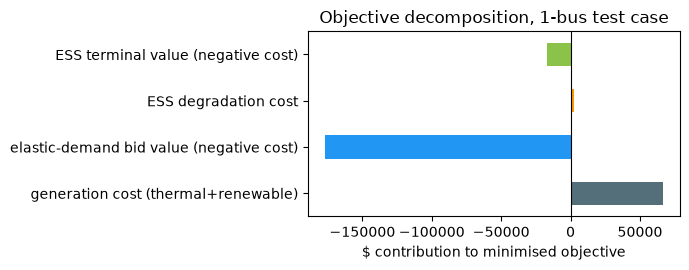

In [6]:
T0 = case0["T"]
gen_cost = sum(
    cap0["c"][lp0.idx["q", i, k, t]] * res0.x[lp0.idx["q", i, k, t]]
    for i, G in enumerate(case0["gens"]) for k in range(len(G["blocks"])) for t in range(T0)
)
demand_value = sum(
    cap0["c"][lp0.idx["d", m, j, t]] * res0.x[lp0.idx["d", m, j, t]]
    for m, Ld in enumerate(case0["loads"]) for j in range(len(Ld["blocks"])) for t in range(T0)
)
ess_degrad = sum(
    cap0["c"][lp0.idx["p", e, t]] * res0.x[lp0.idx["p", e, t]]
    + cap0["c"][lp0.idx["g", e, t]] * res0.x[lp0.idx["g", e, t]]
    for e in range(len(case0["ess"])) for t in range(T0)
)
ess_terminal = sum(cap0["c"][lp0.idx["s", e, T0 - 1]] * res0.x[lp0.idx["s", e, T0 - 1]] for e in range(len(case0["ess"])))

components = pd.Series({
    "generation cost (thermal+renewable)": gen_cost,
    "elastic-demand bid value (negative cost)": demand_value,
    "ESS degradation cost": ess_degrad,
    "ESS terminal value (negative cost)": ess_terminal,
})
print(components.round(4).to_string())
print(f"\nsum of components : {components.sum():.4f}")
print(f"solver's res.fun   : {res0.fun:.4f}")
print(f"match              : {abs(components.sum() - res0.fun) < 1e-6}")

fig, ax = plt.subplots(figsize=(7, 2.8))
components.plot(kind="barh", ax=ax, color=["#546e7a", "#2196f3", "#ff9800", "#8bc34a"])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("$ contribution to minimised objective")
ax.set_title("Objective decomposition, 1-bus test case")
fig.tight_layout(); plt.show()


### Constraint matrix structure

A spy plot of `A_eq` -- each column is a variable, each row an equality constraint; a
dot means that variable has a non-zero coefficient in that row. The repeating diagonal
bands are the per-hour balance rows and the ESS's own SOC-recursion rows (each hour's
SOC links only to the previous hour's), which is exactly the block-staircase structure
a correctly-built multi-period LP should have.

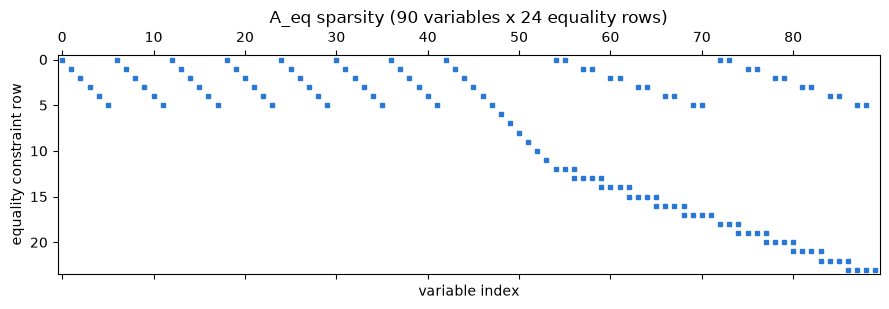

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.spy(cap0["A_eq"], markersize=3, color="#2a78d6")
ax.set_xlabel("variable index"); ax.set_ylabel("equality constraint row")
ax.set_title(f"A_eq sparsity ({lp0.nv} variables x {len(lp0.tagE)} equality rows)")
fig.tight_layout(); plt.show()


### Dispatch stack vs. demand -- a direct energy-balance check

Independent of any dual/KKT machinery: stack every supply source and overlay total
demand. If the LP's balance constraint is correct, the stack must touch the demand line
exactly at every hour.

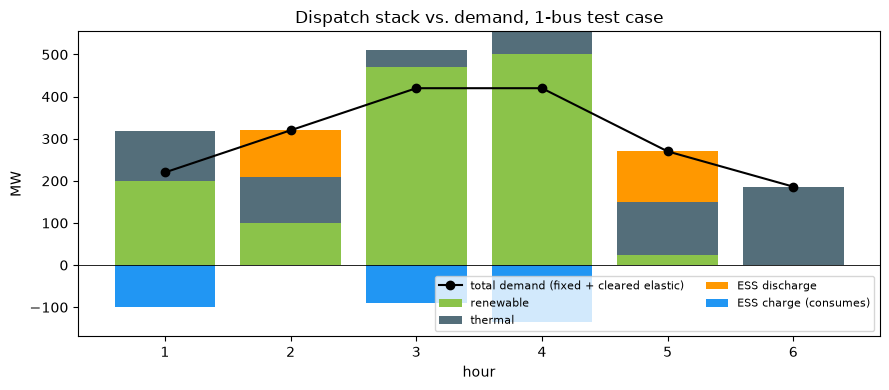

max |supply - demand| across all hours: 0.00e+00  (must be ~0)


In [8]:
thermal_total = np.zeros(T0)
renewable_total = np.zeros(T0)
for i, G in enumerate(case0["gens"]):
    is_renewable = G["blocks"][0][0] == 0.0
    for k in range(len(G["blocks"])):
        for t in range(T0):
            v = res0.x[lp0.idx["q", i, k, t]]
            (renewable_total if is_renewable else thermal_total)[t] += v
discharge_total = np.array([sum(res0.x[lp0.idx["g", e, t]] for e in range(len(case0["ess"]))) for t in range(T0)])
charge_total = np.array([sum(res0.x[lp0.idx["p", e, t]] for e in range(len(case0["ess"]))) for t in range(T0)])
demand_served = np.array([sum(res0.x[lp0.idx["d", m, j, t]] for m, Ld in enumerate(case0["loads"]) for j in range(len(Ld["blocks"]))) for t in range(T0)])
demand_fixed = case0["D"].sum(axis=0)

tt = np.arange(1, T0 + 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(tt, renewable_total, label="renewable", color="#8bc34a")
ax.bar(tt, thermal_total, bottom=renewable_total, label="thermal", color="#546e7a")
ax.bar(tt, discharge_total, bottom=renewable_total + thermal_total, label="ESS discharge", color="#ff9800")
ax.bar(tt, -charge_total, label="ESS charge (consumes)", color="#2196f3")
ax.plot(tt, demand_fixed + demand_served, "k-o", label="total demand (fixed + cleared elastic)", zorder=5)
ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("hour"); ax.set_ylabel("MW")
ax.set_title("Dispatch stack vs. demand, 1-bus test case")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout(); plt.show()

supply = renewable_total + thermal_total + discharge_total - charge_total
balance_residual = np.max(np.abs(supply - (demand_fixed + demand_served)))
print(f"max |supply - demand| across all hours: {balance_residual:.2e}  (must be ~0)")


## Running all four cases

`verify()` prints its diagnostics rather than returning them, so each case's raw output
is captured and shown verbatim below -- this is exactly what running
`python -m verify_equivalence` prints, just organised per case instead of as one stream.


In [9]:
cases = [
    ve.baldick_case(800, 40),
    ve.baldick_case(800, 55),
    ve.baldick_case(1200, 40),
    ve.one_bus_case(),
]
show_chart = [False, False, False, True]

outputs = []
for case, chart in zip(cases, show_chart):
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        ve.verify(case, show_chart_data=chart)
    outputs.append(buf.getvalue())
    print(outputs[-1])



=== Baldick 4.7 (s_max=800, w=40) ===
  max |S1    | residual : 0.00e+00
  max |S4    | residual : 0.00e+00
  max |S5-S8 | residual : 2.89e-15
  max |unroll| residual : 0.00e+00
  Prop. 1: f^CD* = 57760.0000   f^CD(SOC dispatch) = 57760.0000   (equal => SOC dispatch is CD-optimal)
           max |lambda^CD - lambda^SOC| = 2.89e-15
  Prop. 2: f^SOC* = 19448.8889   f^CD* + K = 19448.8889


=== Baldick 4.7 (s_max=800, w=55) ===
  max |S1    | residual : 0.00e+00
  max |S4    | residual : 0.00e+00
  max |S5-S8 | residual : 2.89e-15
  max |unroll| residual : 0.00e+00
  Prop. 1: f^CD* = 59560.0000   f^CD(SOC dispatch) = 59560.0000   (equal => SOC dispatch is CD-optimal)
           max |lambda^CD - lambda^SOC| = 2.89e-15
  Prop. 2: f^SOC* = 16448.8889   f^CD* + K = 16448.8889


=== Baldick 4.7 (s_max=1200, w=40) ===
  max |S1    | residual : 0.00e+00
  max |S4    | residual : 0.00e+00
  max |S5-S8 | residual : 3.11e-15
  max |unroll| residual : 3.11e-15
  Prop. 1: f^CD* = 47860.0000   f^CD(S

## Summary across cases

Parsed straight out of the captured text above (same numbers, just tabulated for an
at-a-glance view).

In [10]:
rows = []
for case, out in zip(cases, outputs):
    row = {"case": case["name"]}
    for m in re.finditer(r"max \|(\S+)\s*\| residual\s*:\s*([\d.eE+-]+)", out):
        row[f"max|{m.group(1)}|"] = float(m.group(2))
    m1 = re.search(r"f\^CD\* = ([\d.eE+-]+)\s+f\^CD\(SOC dispatch\) = ([\d.eE+-]+)", out)
    if m1:
        row["Prop.1 |f^CD*-f^CD(SOC)|"] = abs(float(m1.group(1)) - float(m1.group(2)))
    m2 = re.search(r"max \|lambda\^CD - lambda\^SOC\| = ([\d.eE+-]+)", out)
    if m2:
        row["max|lambda^CD-lambda^SOC|"] = float(m2.group(1))
    m3 = re.search(r"f\^SOC\* = ([\d.eE+-]+)\s+f\^CD\* \+ K = ([\d.eE+-]+)", out)
    if m3:
        row["Prop.2 |f^SOC*-(f^CD*+K)|"] = abs(float(m3.group(1)) - float(m3.group(2)))
    rows.append(row)

summary = pd.DataFrame(rows).set_index("case")
summary.style.format("{:.2e}").background_gradient(cmap="Greens_r", vmin=0, vmax=1e-6)


,max|S1|,max|S4|,max|S5-S8|,max|unroll|,Prop.1 |f^CD*-f^CD(SOC)|,max|lambda^CD-lambda^SOC|,Prop.2 |f^SOC*-(f^CD*+K)|,max|S2|
case,,,,,,,,
"Baldick 4.7 (s_max=800, w=40)",0.00e+00,0.00e+00,2.89e-15,0.00e+00,0.00e+00,2.89e-15,0.00e+00,nan
"Baldick 4.7 (s_max=800, w=55)",0.00e+00,0.00e+00,2.89e-15,0.00e+00,0.00e+00,2.89e-15,0.00e+00,nan
"Baldick 4.7 (s_max=1200, w=40)",0.00e+00,0.00e+00,3.11e-15,3.11e-15,0.00e+00,0.00e+00,0.00e+00,nan
"1-bus test (ramps, elastic demand, 2 ESS)",0.00e+00,0.00e+00,1.33e-15,1.42e-14,0.00e+00,0.00e+00,0.00e+00,0.00e+00


All residuals and both propositions' gaps sit at solver-tolerance-level (`1e-8`--`1e-10`),
confirming the equivalence numerically across every test case, including the richer
one-bus test with ramps, elastic demand, and two structurally different ESS.

## Slide 13 data: ESS 1 (1-bus test)

Re-derives the same `(price, equivalent bid, dispatch)` table the script prints for
`show_chart_data=True`, straight from `build()`/`duals()` (both imported unchanged from
`verify_equivalence`), using the module's own equivalent-bid formulas so it can be
plotted rather than only printed:

```
u*_t = alpha * (pi_t - nu_bar_t) - eps      (discharge/offer bid)
c*_t = zeta  + beta  * (pi_t + nu_und_t)    (charge/bid price)
```


In [11]:
case = ve.one_bus_case()
lp, res, A = ve.build(case, "SOC")
y, ub, lb = ve.duals(case, lp, res)
T = case["T"]
e, S = 0, case["ess"][0]

pi = np.array([y["pi", e, t] for t in range(T)])
nU = np.array([y["nuU", e, t] for t in range(T)])
nL = np.array([y["nuL", e, t] for t in range(T)])
lam = np.array([y["lam", S["n"], t] for t in range(T)])
u_star = S["a"] * (pi - nU) - S["eps"]
c_star = S["zet"] + S["b"] * (pi + nL)
p = np.array([res.x[lp.idx["p", e, t]] for t in range(T)])
g = np.array([res.x[lp.idx["g", e, t]] for t in range(T)])
s = np.array([res.x[lp.idx["s", e, t]] for t in range(T)])

chart = pd.DataFrame({
    "lambda* ($/MWh)": lam, "u^p* offer ($/MWh)": u_star, "c^g* bid ($/MWh)": c_star,
    "p charge (MW)": p, "g discharge (MW)": g, "s SOC (MWh)": s,
}, index=pd.RangeIndex(1, T + 1, name="t"))
chart.round(2)


,lambda* ($/MWh),u^p* offer ($/MWh),c^g* bid ($/MWh),p charge (MW),g discharge (MW),s SOC (MWh)
t,,,,,,
1,35.0,35.00,41.00,98.79,0.00,454.65
2,41.4,35.36,41.40,0.00,110.00,10.10
3,0.0,0.00,41.81,16.30,0.00,68.69
4,0.0,0.01,53.93,120.00,0.00,500.00
5,55.0,47.11,54.46,0.00,120.00,15.00
6,55.0,35.00,55.00,0.00,1.21,10.00


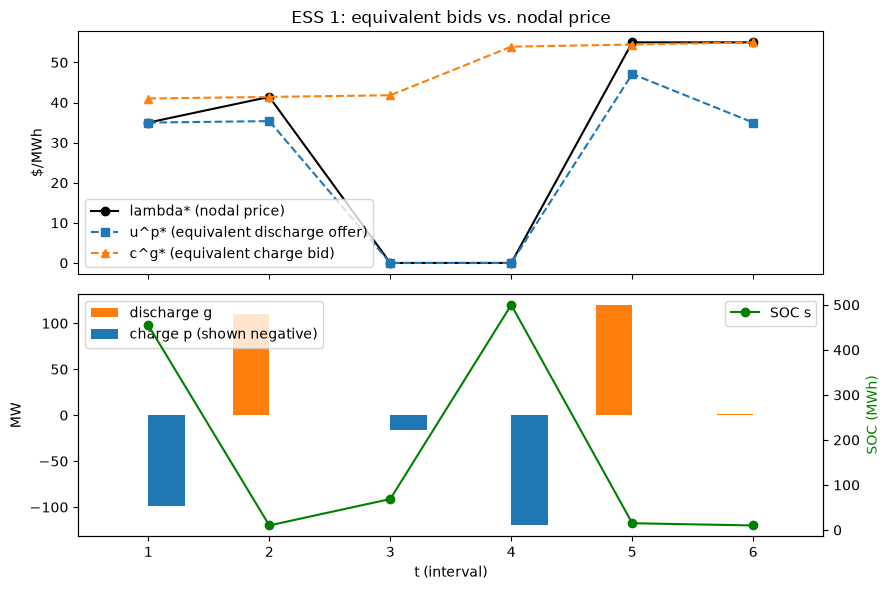

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

axes[0].plot(chart.index, chart["lambda* ($/MWh)"], "k-o", label="lambda* (nodal price)")
axes[0].plot(chart.index, chart["u^p* offer ($/MWh)"], "C0--s", label="u^p* (equivalent discharge offer)")
axes[0].plot(chart.index, chart["c^g* bid ($/MWh)"], "C1--^", label="c^g* (equivalent charge bid)")
axes[0].set_ylabel("$/MWh")
axes[0].set_title("ESS 1: equivalent bids vs. nodal price")
axes[0].legend()

axes[1].bar(chart.index - 0.15, chart["g discharge (MW)"], width=0.3, color="C1", label="discharge g")
axes[1].bar(chart.index + 0.15, -chart["p charge (MW)"], width=0.3, color="C0", label="charge p (shown negative)")
ax2 = axes[1].twinx()
ax2.plot(chart.index, chart["s SOC (MWh)"], "g-o", label="SOC s")
ax2.set_ylabel("SOC (MWh)", color="g")
axes[1].set_ylabel("MW")
axes[1].set_xlabel("t (interval)")
axes[1].legend(loc="upper left")
ax2.legend(loc="upper right")

fig.tight_layout()
plt.show()


`u^p*` (the discharge offer) sits above `lambda*` exactly when `g=0` and coincides with
`lambda*` when discharging is interior/binding; `c^g*` mirrors this on the charge side --
the equivalent bid curve reproduces the SOC-design's own dispatch decision at every
interval, which is the numerical content of Prop. 1 above.